=== Section 5.3 Worked Example Check ===
Clip window: (10,10) - (50,50)
Line: P1(5,30) -> P2(60,30)
Program output : (10, 30.0, 50, 30.0)
Expected (5.3) : (10, 30, 50, 30)
Result: MATCH ✔
Saved before/after demo plot to theory_example_result.png

Line (0,0)-(9,9) -> Clipped to (2.00,2.00)-(8.00,8.00)
Line (0,4)-(10,6) -> Clipped to (2.00,4.40)-(8.00,5.60)
Line (5,0)-(5,10) -> Clipped to (5.00,2.00)-(5.00,8.00)
Line (3,3)-(6,7) -> Clipped to (3.00,3.00)-(6.00,7.00)

Saved visualization to clipping_result.png

--- Window-to-Viewport Transformation Example ---
World (0,0) -> Viewport (0.0, 0.0)
World (5,5) -> Viewport (250.0, 200.0)
World (10,10) -> Viewport (500.0, 400.0)
World (2,8) -> Viewport (100.0, 320.0)


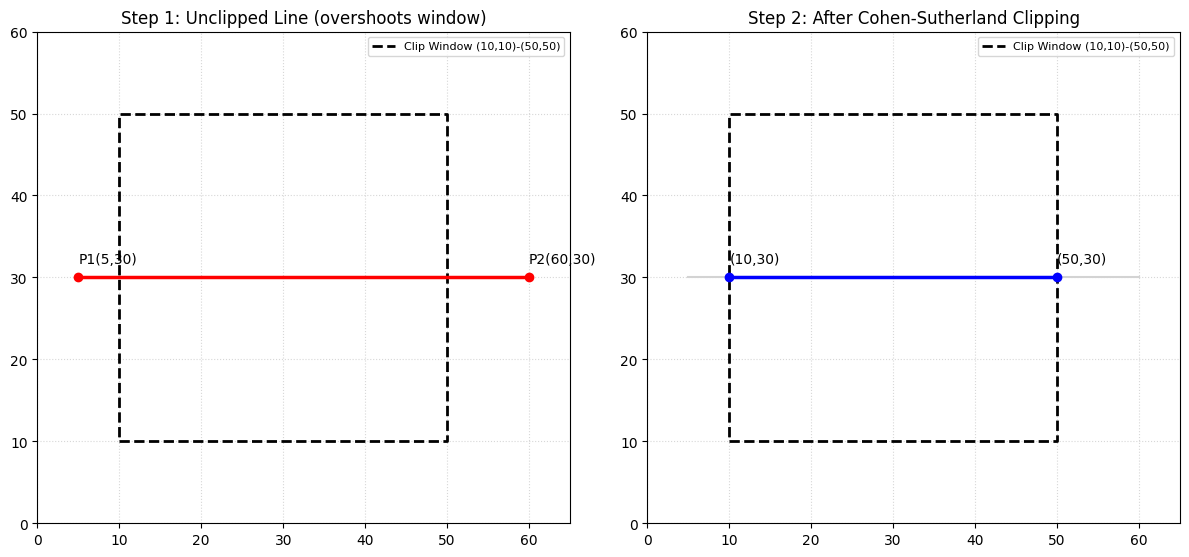

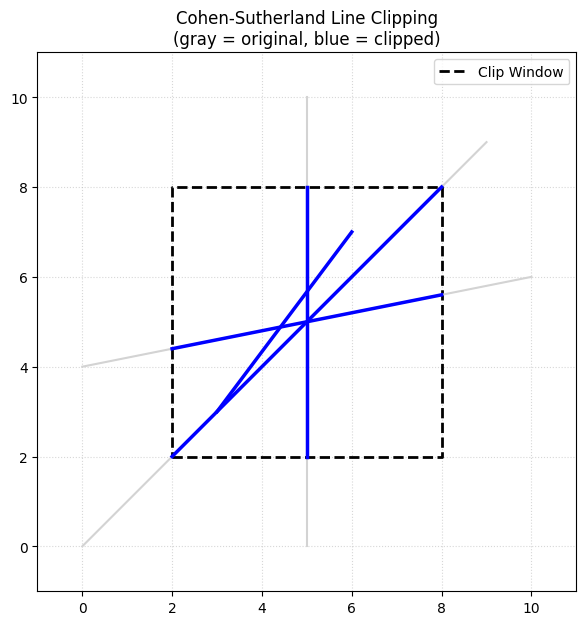

In [7]:
import matplotlib.pyplot as plt
import os
os.makedirs("outputs", exist_ok=True)

def window_to_viewport(x, y, wx_min, wx_max, wy_min, wy_max,
                        vx_min, vx_max, vy_min, vy_max):

    sx = (vx_max - vx_min) / (wx_max - wx_min)
    sy = (vy_max - vy_min) / (wy_max - wy_min)

    x_new = vx_min + (x - wx_min) * sx
    y_new = vy_min + (y - wy_min) * sy
    return x_new, y_new


INSIDE, LEFT, RIGHT, BOTTOM, TOP = 0, 1, 2, 4, 8


def compute_outcode(x, y, xmin, xmax, ymin, ymax):
    code = INSIDE
    if x < xmin:
        code |= LEFT
    elif x > xmax:
        code |= RIGHT
    if y < ymin:
        code |= BOTTOM
    elif y > ymax:
        code |= TOP
    return code


def cohen_sutherland_clip(x1, y1, x2, y2, xmin, xmax, ymin, ymax):

    outcode1 = compute_outcode(x1, y1, xmin, xmax, ymin, ymax)
    outcode2 = compute_outcode(x2, y2, xmin, xmax, ymin, ymax)
    accept = False

    while True:
        if outcode1 == 0 and outcode2 == 0:

            accept = True
            break
        elif outcode1 & outcode2 != 0:

            break
        else:

            x, y = 0.0, 0.0
            outcode_out = outcode1 if outcode1 != 0 else outcode2

            if outcode_out & TOP:
                x = x1 + (x2 - x1) * (ymax - y1) / (y2 - y1)
                y = ymax
            elif outcode_out & BOTTOM:
                x = x1 + (x2 - x1) * (ymin - y1) / (y2 - y1)
                y = ymin
            elif outcode_out & RIGHT:
                y = y1 + (y2 - y1) * (xmax - x1) / (x2 - x1)
                x = xmax
            elif outcode_out & LEFT:
                y = y1 + (y2 - y1) * (xmin - x1) / (x2 - x1)
                x = xmin

            if outcode_out == outcode1:
                x1, y1 = x, y
                outcode1 = compute_outcode(x1, y1, xmin, xmax, ymin, ymax)
            else:
                x2, y2 = x, y
                outcode2 = compute_outcode(x2, y2, xmin, xmax, ymin, ymax)

    if accept:
        return (x1, y1, x2, y2)
    return None



def test_theory_example(verbose=True):
    xmin, xmax, ymin, ymax = 10, 50, 10, 50
    x1, y1, x2, y2 = 5, 30, 60, 30
    expected = (10, 30, 50, 30)

    result = cohen_sutherland_clip(x1, y1, x2, y2, xmin, xmax, ymin, ymax)
    passed = result is not None and tuple(round(v, 6) for v in result) == expected

    if verbose:
        print("=== Section 5.3 Worked Example Check ===")
        print(f"Clip window: ({xmin},{ymin}) - ({xmax},{ymax})")
        print(f"Line: P1({x1},{y1}) -> P2({x2},{y2})")
        print(f"Program output : {result}")
        print(f"Expected (5.3) : {expected}")
        print("Result: MATCH ✔" if passed else "Result: MISMATCH ✘")

    assert passed, f"Expected {expected}, got {result}"
    return result


def plot_theory_example(save_path="theory_example_result.png"):

    xmin, xmax, ymin, ymax = 10, 50, 10, 50
    x1, y1, x2, y2 = 5, 30, 60, 30
    cx1, cy1, cx2, cy2 = cohen_sutherland_clip(x1, y1, x2, y2, xmin, xmax, ymin, ymax)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    for ax, title in zip(axes, ["Step 1: Unclipped Line (overshoots window)",
                                 "Step 2: After Cohen-Sutherland Clipping"]):
        ax.plot([xmin, xmax, xmax, xmin, xmin],
                 [ymin, ymin, ymax, ymax, ymin],
                 'k--', linewidth=2, label='Clip Window (10,10)-(50,50)')
        ax.set_xlim(0, 65)
        ax.set_ylim(0, 60)
        ax.set_aspect('equal')
        ax.set_title(title)
        ax.grid(True, linestyle=':', alpha=0.5)
        ax.legend(loc='upper right', fontsize=8)


    axes[0].plot([x1, x2], [y1, y2], color='red', linewidth=2.5, marker='o',
                 label='_nolegend_')
    axes[0].annotate(f'P1({x1},{y1})', (x1, y1), textcoords="offset points",
                      xytext=(0, 10))
    axes[0].annotate(f'P2({x2},{y2})', (x2, y2), textcoords="offset points",
                      xytext=(0, 10))


    axes[1].plot([x1, x2], [y1, y2], color='lightgray', linewidth=1.5)
    axes[1].plot([cx1, cx2], [cy1, cy2], color='blue', linewidth=2.5, marker='o',
                 label='_nolegend_')
    axes[1].annotate(f'({cx1:.0f},{cy1:.0f})', (cx1, cy1), textcoords="offset points",
                      xytext=(0, 10))
    axes[1].annotate(f'({cx2:.0f},{cy2:.0f})', (cx2, cy2), textcoords="offset points",
                      xytext=(0, 10))

    plt.tight_layout()
    plt.savefig("outputs/theory_example_result.png")
    print(f"Saved before/after demo plot to {save_path}")


if __name__ == "__main__":

    test_theory_example()
    plot_theory_example()
    print()


    xmin, xmax, ymin, ymax = 2, 8, 2, 8


    lines = [
    (0, 0, 9, 9),
    (0, 4, 10, 6),
    (5, 0, 5, 10),
    (3, 3, 6, 7),
    ]

    fig, ax = plt.subplots(figsize=(7, 7))


    ax.plot([xmin, xmax, xmax, xmin, xmin],
             [ymin, ymin, ymax, ymax, ymin],
             'k--', linewidth=2, label='Clip Window')

    for (x1, y1, x2, y2) in lines:

        ax.plot([x1, x2], [y1, y2], color='lightgray', linewidth=1.5)

        clipped = cohen_sutherland_clip(x1, y1, x2, y2, xmin, xmax, ymin, ymax)
        if clipped:
            cx1, cy1, cx2, cy2 = clipped
            ax.plot([cx1, cx2], [cy1, cy2], color='blue', linewidth=2.5)
            print(f"Line ({x1},{y1})-({x2},{y2}) -> Clipped to "
                  f"({cx1:.2f},{cy1:.2f})-({cx2:.2f},{cy2:.2f})")
        else:
            print(f"Line ({x1},{y1})-({x2},{y2}) -> Rejected (fully outside)")

    ax.set_xlim(-1, 11)
    ax.set_ylim(-1, 11)
    ax.set_aspect('equal')
    ax.set_title("Cohen-Sutherland Line Clipping\n(gray = original, blue = clipped)")
    ax.legend()
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.savefig("clipping_result.png")
    print("\nSaved visualization to clipping_result.png")


    print("\n--- Window-to-Viewport Transformation Example ---")

    world_points = [(0, 0), (5, 5), (10, 10), (2, 8)]
    for (x, y) in world_points:
        vx, vy = window_to_viewport(x, y, 0, 10, 0, 10, 0, 500, 0, 400)
        print(f"World ({x},{y}) -> Viewport ({vx:.1f}, {vy:.1f})")

    plt.show()